<img src="https://heig-vd.ch/docs/default-source/doc-global-newsletter/2020-slim.svg" alt="Logo HEIG-VD" style="width: 80px;" align="right"/>

# Cours APN - Labo 5 : Groupement de clients avec _k_-moyennes

Le but de ce laboratoire est de diviser en groupes cohérents les clients d'un centre commercial, en utilisant la méthode des [_k_-moyennes implémentée dans Scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

Les données viennent de Kaggle: [Mall Customer Segmentation](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) (fournies avec le notebook).  Il n'y a pas d'annotation de référence des groupes, donc ce sera à vous de juger leur qualité grâce à la visualisation.  

Le travail comporte les étapes suivantes :
1. Analyse exploratoire des données.
2. Application simple des _k_-moyennes en 2D.
3. Améliorations: optimisation du nombre de groupes, 3D.

Veuillez répondre aux questions de chaque étape en écrivant d'abord les commandes nécessaires, puis en commentant le résultat si nécessaire.

Il est conseillé de créer un nouvel environnement Conda pour le cours d'APN, par exemple en utilisant la commande `conda create -n cours_apn --file requirements.txt`.  Le fichier _requirements.txt_ fourni avec le notebook liste les packages à installer. 

***
**Étudiants :** Ismael Giovannetti & Mouhamed Sakho
***

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.cluster import KMeans

## 1. Analyse exploratoire des données

Veuillez lire les données du fichier `Mail_Customers.csv` dans une *data frame* Pandas nommée `clients_df` et examinez-la.  Veuillez répondre aux questions suivantes en utilisant les commandes appropriées.

a. Combien de clients figurent dans les données ?<br>
b. Combien d'attributs y a-t-il pour chaque client ?  Quels sont leurs noms ?<br>
c. Y a-t-il des données manquantes ?<br>
d. Quel est le *5 number summary* pour chaque attribut?

In [2]:
# Lecture des données
clients_df = pd.read_csv("Mall_Customers.csv")

# a. Nombre de clients (lignes) et b. nombre d'attributs (colonnes) + leurs noms
print("Forme (lignes, colonnes) :", clients_df.shape)
print("Noms des colonnes :", list(clients_df.columns))

# c. Données manquantes : nombre de NaN par colonne
print("\nValeurs manquantes par colonne :")
print(clients_df.isna().sum())

# d. 5 number summary (min, Q1, médiane, Q3, max)
print("\n5 number summary :")
clients_df.describe().loc[["min", "25%", "50%", "75%", "max"]]

Forme (lignes, colonnes) : (200, 5)
Noms des colonnes : ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Valeurs manquantes par colonne :
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

5 number summary :


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
min,1.00,18.00,15.0,1.00
25%,50.75,28.75,41.5,34.75
50%,100.50,36.00,61.5,50.00
75%,150.25,49.00,78.0,73.00
max,200.00,70.00,137.0,99.00


**Réponses :**
* **a.** 200 clients.
* **b.** 5 attributs : `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.
* **c.** Aucune donnée manquante (0 `NaN` dans chaque colonne).
* **d.** Voir le tableau ci-dessus. `CustomerID` n'est qu'un identifiant et `Gender` est catégoriel : seuls `Age`, `Annual Income` et `Spending Score` ont un sens statistique.

e. Combien de personnes sont des femmes, et combien des hommes ?<br>
f. Quel est le revenu annuel moyen par sexe ? Quel est le *spending score* moyen par sexe ?<br>
g. Quelles sont les valeurs extrêmes de l'âge pour les femmes ? Et pour les hommes ?<br>
h. Même question pour le revenu annuel, puis pour le *spending score*.<br>

In [4]:
# e. Nombre de femmes et d'hommes
print("Effectifs par sexe :")
print(clients_df["Gender"].value_counts())

# f. Revenu annuel moyen et spending score moyen par sexe
print("\nMoyennes par sexe :")
print(clients_df.groupby("Gender")[["Annual Income (k$)", "Spending Score (1-100)"]].mean())

# g. et h. Valeurs extrêmes (min et max) de l'âge, du revenu et du spending score par sexe
print("\nValeurs extrêmes par sexe :")
clients_df.groupby("Gender")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].agg(["min", "max"])

Effectifs par sexe :
Gender
Female    112
Male       88
Name: count, dtype: int64

Moyennes par sexe :
        Annual Income (k$)  Spending Score (1-100)
Gender                                            
Female           59.250000               51.526786
Male             62.227273               48.511364

Valeurs extrêmes par sexe :


Age     Annual Income (k$)      Spending Score (1-100)    
       min max                min  max                    min max
Gender                                                           
Female  18  68                 16  126                      5  99
Male    18  70                 15  137                      1  97

## 2. Groupement simple avec la méthode des k-moyennes

### 2a. Groupement avec deux attributs, en trois groupes

Pour commencer, veuillez utiliser la méthode [sklearn.cluster.KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) avec initialisation aléatoire, un seul essai, et en fixant le nombre de groupes à trois (3).  De plus, veuillez utiliser seulement les colonnes 'Annual Income (k$)' et 'Spending Score (1-100)' des données.

In [5]:
# Données utilisées : revenu annuel et spending score uniquement
cols_2d = ["Annual Income (k$)", "Spending Score (1-100)"]
X2 = clients_df[cols_2d]

# k-moyennes : 3 groupes, initialisation aléatoire, un seul essai
# (random_state fixé pour que le résultat soit reproductible)
km3 = KMeans(n_clusters=3, init="random", n_init=1, random_state=0)
labels3 = km3.fit_predict(X2)

print("Inertie (WSS) :", round(km3.inertia_))
print("Taille des groupes :", np.bincount(labels3))

Inertie (WSS) : 106348
Taille des groupes : [ 38  39 123]


Veuillez afficher les données en 2D (_annual income_ et _spending score_) en indiquant l'appartenance aux clusters par des couleurs différentes.  Veuillez utiliser des marqueurs différents pour les hommes et pour les femmes.

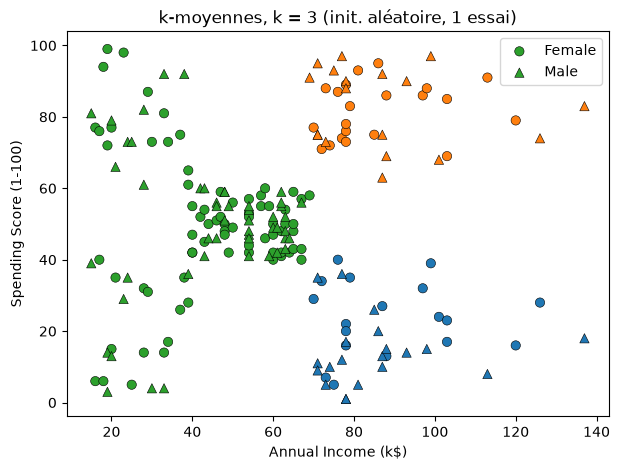

In [6]:
def plot_clusters_2d(df, labels, centers=None, title=""):
    """Nuage revenu / score : couleur = groupe, marqueur = sexe (rond = femme, triangle = homme)."""
    fig, ax = plt.subplots(figsize=(7, 5))
    cmap = plt.get_cmap("tab10")
    for gender, marker in [("Female", "o"), ("Male", "^")]:
        mask = (df["Gender"] == gender).to_numpy()
        ax.scatter(df.loc[mask, cols_2d[0]], df.loc[mask, cols_2d[1]],
                   c=[cmap(l) for l in labels[mask]], marker=marker,
                   edgecolor="k", linewidth=0.4, s=45, label=gender)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="k", marker="*", s=250, label="Centroïdes")
    ax.set_xlabel(cols_2d[0])
    ax.set_ylabel(cols_2d[1])
    ax.set_title(title)
    ax.legend()
    plt.show()

plot_clusters_2d(clients_df, labels3, title="k-moyennes, k = 3 (init. aléatoire, 1 essai)")

**Question :** comment appréciez-vous la qualité du groupement obtenu ?  Veuillez la discuter. 

**Réponse :** le groupement à 3 groupes est de mauvaise qualité (inertie élevée : ~106 000).

À l'œil, le nuage de points forme clairement **5 blocs** : un bloc central (revenu et score moyens) et quatre blocs aux coins (revenu bas / haut combiné avec score bas / haut). Avec k = 3, K-Means doit fusionner certains de ces blocs :
* il sépare bien les clients à revenu élevé en deux groupes (score bas / score élevé) ;
* mais le grand groupe restant (123 clients) fusionne le bloc central avec les deux blocs « revenu bas » (score bas et score élevé).

Ce groupe n'est pas homogène : il mélange des clients qui dépensent très peu, très beaucoup ou moyennement, donc il est difficile à interpréter. Le nombre de groupes est trop petit pour cette structure.

Les marqueurs hommes / femmes sont mélangés dans tous les groupes : le sexe ne structure pas les données.

### 2b. Choix individuel d'un nombre de groupes plus adapté

Sur la base de la question précédente, veuillez effectuer le groupement avec le nombre de groupes qui vous semble le plus adapté, autre que 3.  Veuillez effectuer 10 initialisations aléatoires.

Pour l'affichage, veuillez afficher également les centroïdes des groupes (obtenus de `KMeans`), en utilisant une étoile noire. 

In [8]:
# D'après la figure précédente, 5 groupes semblent les plus adaptés.
# 10 initialisations aléatoires : K-Means garde la meilleure (inertie minimale).
km5 = KMeans(n_clusters=5, init="random", n_init=10, random_state=0)
labels5 = km5.fit_predict(X2)

print("Inertie (WSS) :", round(km5.inertia_))
print("Taille des groupes :", np.bincount(labels5))
print("Centroïdes (revenu, score) :")
print(km5.cluster_centers_.round(1))

Inertie (WSS) : 44448
Taille des groupes : [23 39 81 35 22]
Centroïdes (revenu, score) :
[[26.3 20.9]
 [86.5 82.1]
 [55.3 49.5]
 [88.2 17.1]
 [25.7 79.4]]


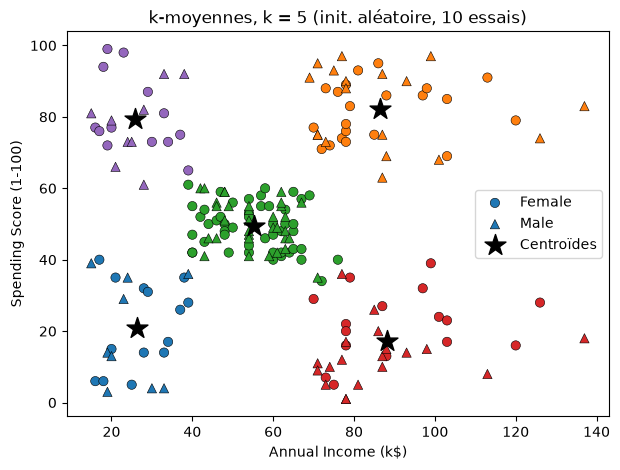

In [9]:
plot_clusters_2d(clients_df, labels5, centers=km5.cluster_centers_,
                 title="k-moyennes, k = 5 (init. aléatoire, 10 essais)")

**Question :** comment appréciez-vous la qualité du nouveau groupement ?  Veuillez la discuter. 
    
Pouvez-vous décrire chaque groupe en fonction des valeurs des deux axes ?

**Réponse :** le groupement à 5 groupes est bien meilleur : les groupes sont compacts, bien séparés et correspondent aux blocs visibles à l'œil. L'inertie passe de ~106 000 (k = 3) à ~44 000.

Description des groupes (revenu en k$, score de 1 à 100) :

| Groupe | Centroïde (revenu, score) | Interprétation |
|---|---|---|
| Revenu bas, score bas | ~(26, 21) | clients modestes qui dépensent peu |
| Revenu bas, score élevé | ~(26, 79) | clients modestes mais gros dépensiers |
| Revenu moyen, score moyen | ~(55, 50) | le plus grand groupe, clientèle « standard » |
| Revenu élevé, score bas | ~(88, 17) | clients aisés qui dépensent peu (cible marketing) |
| Revenu élevé, score élevé | ~(87, 82) | clients aisés et gros dépensiers (meilleurs clients) |

Le sexe (marqueurs) est réparti dans tous les groupes.

## 3. Groupements optimisés en 3D

Dans cette section, vous allez utiliser l'initialisation k-means++ (un seul tirage), et optimiser le nombre de groupes par la méthode du coude (_elbow_).  Puis, vous allez ajouter la dimension de l'âge et afficher les groupes en 3D.

### 3a. Méthode du coude et initialisation k-means++

Dans tout ce qui suit, vous allez initialiser les centroïdes avec k-means++ (paramètre `init`) et exécuter 5 fois l'algorithme des k-moyennes (paramètre `n_init`).

Veuillez afficher les valeurs du coefficient WSS (Within-cluster Sum of Squares) ou **inertie** pour un nombre de groupes variant de 1 à 9.  Travaillez pour l'instant en deux dimensions, comme avant.

k = 1 : inertie = 269,981
k = 2 : inertie = 181,364
k = 3 : inertie = 106,348
k = 4 : inertie = 73,680
k = 5 : inertie = 44,448
k = 6 : inertie = 37,266
k = 7 : inertie = 30,260
k = 8 : inertie = 25,051
k = 9 : inertie = 22,210


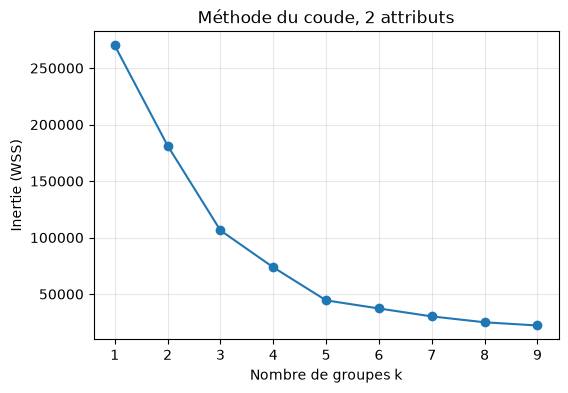

In [11]:
# Inertie (WSS) pour k = 1 ... 9, avec init k-means++ et 5 exécutions (n_init=5)
ks = range(1, 10)
inertias_2d = []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=5, random_state=0).fit(X2)
    inertias_2d.append(km.inertia_)

for k, w in zip(ks, inertias_2d):
    print(f"k = {k} : inertie = {w:,.0f}")

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias_2d, "o-")
plt.xlabel("Nombre de groupes k")
plt.ylabel("Inertie (WSS)")
plt.title("Méthode du coude, 2 attributs")
plt.xticks(list(ks))
plt.grid(True, alpha=0.3)
plt.show()

**Question :** quel est le nombre de groupes qui est optimal d'après cette méthode ?

**Réponse :** le coude se situe à **k = 5**. L'inertie chute fortement de k = 1 à k = 5 (270 000 → 44 000), puis ne baisse plus que lentement (37 000, 30 000, 25 000, …). Au-delà de 5, ajouter un groupe ne fait que découper des groupes déjà compacts.

Le nombre optimal de groupes est donc 5, ce qui confirme le choix visuel du 2b.

Veuillez effectuer le groupement avec le nombre de groupes optimal et les paramètres indiqués pour cette section.  

Veuillez **afficher le résultat** avec le même format que dans la figure précédente.

In [13]:
# Groupement avec k optimal = 5, init k-means++, 5 exécutions
km5pp = KMeans(n_clusters=5, init="k-means++", n_init=5, random_state=0)
labels5pp = km5pp.fit_predict(X2)

print("Inertie (WSS) :", round(km5pp.inertia_))
print("Taille des groupes :", np.bincount(labels5pp))
print("Centroïdes (revenu, score) :")
print(km5pp.cluster_centers_.round(1))

Inertie (WSS) : 44448
Taille des groupes : [81 39 35 23 22]
Centroïdes (revenu, score) :
[[55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]
 [26.3 20.9]
 [25.7 79.4]]


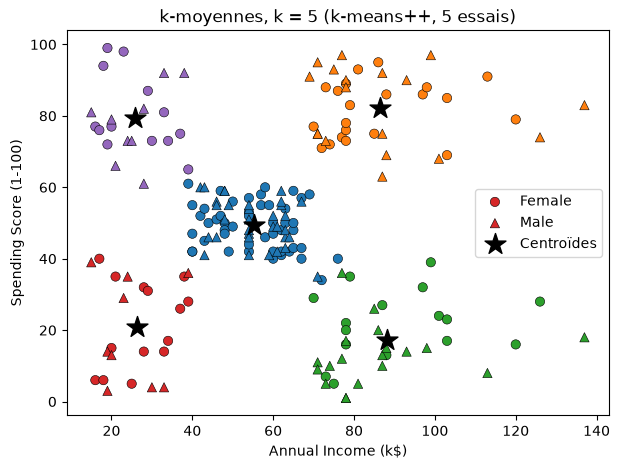

In [14]:
plot_clusters_2d(clients_df, labels5pp, centers=km5pp.cluster_centers_,
                 title="k-moyennes, k = 5 (k-means++, 5 essais)")

**Question :** comment se compare ce groupement à celui obtenu au 2b ?

**Réponse :** le groupement est pratiquement identique à celui du 2b : mêmes 5 groupes, mêmes centroïdes (~(26, 21), (26, 79), (55, 50), (88, 17), (87, 82)), même inertie (~44 448) et mêmes tailles. Seul l'ordre des numéros de groupes (donc des couleurs) change.

Cela s'explique : les 5 blocs sont bien séparés, donc K-Means converge vers la même solution optimale quelle que soit l'initialisation, pour peu qu'on fasse plusieurs essais. L'avantage de k-means++ est d'y arriver avec des centroïdes de départ mieux répartis, donc de façon plus fiable et avec moins d'essais (5 au lieu de 10).

Veuillez calculer le nombre de femmes et d'hommes, respectivement, dans chaque groupe.  Dans quels groupes y a-t-il plus d'hommes que de femmes, et quelles sont les propriétés de ces groupes (revenu, score) ?

In [16]:
# Nombre de femmes et d'hommes dans chaque groupe
clients_df["Cluster"] = labels5pp
repartition = pd.crosstab(clients_df["Cluster"], clients_df["Gender"])
repartition["Plus d'hommes ?"] = repartition["Male"] > repartition["Female"]

# Propriétés (centroïdes) de chaque groupe
centres = pd.DataFrame(km5pp.cluster_centers_.round(1), columns=cols_2d)
centres.index.name = "Cluster"
print(repartition)
print()
print(centres)

Gender   Female  Male  Plus d'hommes ?
Cluster                               
0            48    33            False
1            21    18            False
2            16    19             True
3            14     9            False
4            13     9            False

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                      55.3                    49.5
1                      86.5                    82.1
2                      88.2                    17.1
3                      26.3                    20.9
4                      25.7                    79.4


**Réponse :** il n'y a plus d'hommes que de femmes dans **un seul groupe** : celui à revenu élevé et spending score bas (centroïde ~(88, 17)), avec 19 hommes pour 16 femmes. L'écart est très faible.

Dans tous les autres groupes, les femmes sont plus nombreuses (elles sont 112 contre 88 hommes au total). Le sexe n'explique donc pas la structure des groupes : la différence observée est trop petite pour en tirer une conclusion.

### 3b. Groupement utilisant 3 attributs

Veuillez utiliser à partir de maintenant aussi l'attribut de l'âge.  Veuillez déterminer le nombre optimal de groupes par la méthode du coude, et garder l'initialisation k-means++ avec 5 exécutions.  Dans cette section, on vous demande aussi d'afficher les groupes en 3D.

k = 1 : inertie = 308,813
k = 2 : inertie = 212,840
k = 3 : inertie = 143,343
k = 4 : inertie = 104,374
k = 5 : inertie = 75,351
k = 6 : inertie = 58,300
k = 7 : inertie = 51,117
k = 8 : inertie = 44,342
k = 9 : inertie = 40,623


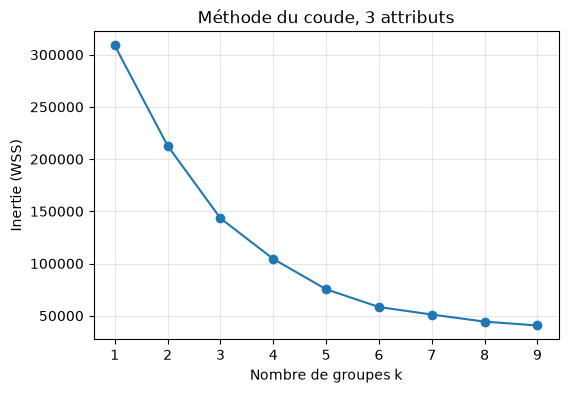

In [18]:
# Méthode du coude avec 3 attributs : âge, revenu annuel, spending score
cols_3d = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X3 = clients_df[cols_3d]

inertias_3d = []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=5, random_state=0).fit(X3)
    inertias_3d.append(km.inertia_)

for k, w in zip(ks, inertias_3d):
    print(f"k = {k} : inertie = {w:,.0f}")

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias_3d, "o-")
plt.xlabel("Nombre de groupes k")
plt.ylabel("Inertie (WSS)")
plt.title("Méthode du coude, 3 attributs")
plt.xticks(list(ks))
plt.grid(True, alpha=0.3)
plt.show()

**Nombre optimal de groupes (3 attributs) :** le coude est moins net qu'en 2D. L'inertie baisse beaucoup jusqu'à k = 6 (308 000 → 58 000), puis très peu (51 000 à k = 7, 44 000 à k = 8). On retient **k = 6**.

In [20]:
# Groupement en 3D avec k = 6, init k-means++, 5 exécutions
km6 = KMeans(n_clusters=6, init="k-means++", n_init=5, random_state=0)
labels6 = km6.fit_predict(X3)

print("Inertie (WSS) :", round(km6.inertia_))
print("Taille des groupes :", np.bincount(labels6))
print("Centroïdes :")
print(pd.DataFrame(km6.cluster_centers_.round(1), columns=cols_3d))

Inertie (WSS) : 58300
Taille des groupes : [38 35 39 45 21 22]
Centroïdes :
    Age  Annual Income (k$)  Spending Score (1-100)
0  27.0                56.7                    49.1
1  41.7                88.2                    17.3
2  32.7                86.5                    82.1
3  56.2                53.4                    49.1
4  44.1                25.1                    19.5
5  25.3                25.7                    79.4


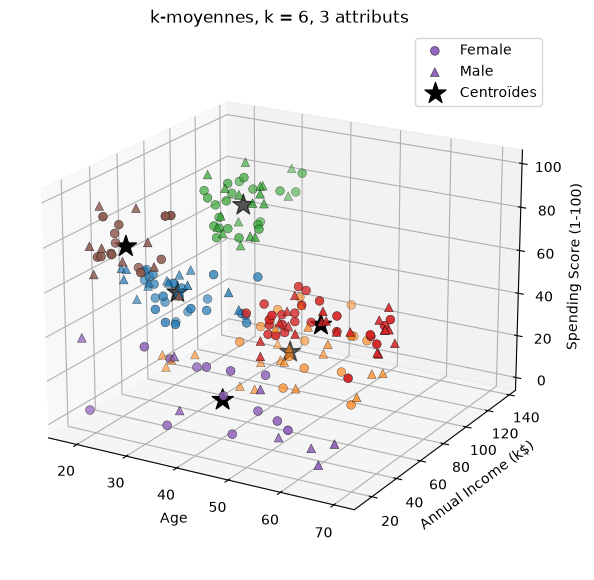

In [21]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
cmap = plt.get_cmap("tab10")
for gender, marker in [("Female", "o"), ("Male", "^")]:
    mask = (clients_df["Gender"] == gender).to_numpy()
    ax.scatter(clients_df.loc[mask, cols_3d[0]], clients_df.loc[mask, cols_3d[1]],
               clients_df.loc[mask, cols_3d[2]], c=[cmap(l) for l in labels6[mask]],
               marker=marker, edgecolor="k", linewidth=0.3, s=40, label=gender)
c = km6.cluster_centers_
ax.scatter(c[:, 0], c[:, 1], c[:, 2], c="k", marker="*", s=250, label="Centroïdes")
ax.set_xlabel(cols_3d[0])
ax.set_ylabel(cols_3d[1])
ax.set_zlabel(cols_3d[2])
ax.set_title("k-moyennes, k = 6, 3 attributs")
ax.view_init(elev=20, azim=-60)
ax.legend()
plt.show()

**Question :** comment se compare ce groupement à celui obtenu au 2b ?

**Réponse :** par rapport au 2b (5 groupes en 2D), on retrouve les mêmes groupes de revenu / score : les centroïdes ont à peu près les mêmes (revenu, score). Seul le groupe « revenu moyen, score moyen » est coupé en deux selon l'âge : ~27 ans (38 clients) et ~56 ans (45 clients).

Les 4 groupes des coins sont inchangés, avec des âges moyens différents :
* revenu bas, score élevé : ~25 ans (jeunes) ;
* revenu élevé, score élevé : ~33 ans ;
* revenu élevé, score bas : ~42 ans ;
* revenu bas, score bas : ~44 ans.

L'âge apporte donc une information supplémentaire (le client dépensier est plutôt jeune), mais il structure moins les données que le revenu et le score : les blocs 2D restent les mêmes et la séparation visuelle est moins nette qu'en 2D. L'inertie n'est pas comparable à celle du 2b, puisqu'elle porte sur 3 dimensions. La 3D est aussi plus difficile à lire, et le choix de k = 6 est plus discutable (coude moins marqué).

**Question :** serait-il difficile d'ajouter le paramètre 'Gender' (avec les valeurs 'Male' et 'Female') comme 4e attribut pour effectuer le groupement ?  Veuillez discuter la pertinence de cette idée.

**Réponse :** techniquement ce n'est pas très difficile : il suffit d'encoder `Gender` en nombres (par exemple Female = 0, Male = 1, ou un *one-hot*) avant d'appeler `KMeans`. Mais ce n'est **pas une bonne idée**, pour plusieurs raisons :
* **Distance et moyenne.** K-Means utilise la distance euclidienne et la moyenne des points pour calculer les centroïdes. Pour une variable binaire, cela n'a pas de sens : un centroïde à 0.4 n'est ni homme ni femme.
* **Échelle.** Une variable valant 0 ou 1 pèse très peu face à l'âge (18-70), au revenu (15-137) ou au score (1-99), donc elle n'influencerait presque pas le groupement. À l'inverse, en la mettant à l'échelle, on lui donnerait un poids arbitraire.
* **Peu de pouvoir discriminant.** Les données montrent que le sexe sépare peu les clients : moyennes de revenu et de score très proches entre hommes et femmes, et sexe réparti dans tous les groupes (cf. 3a).

Pour utiliser vraiment des variables catégorielles, il faudrait une méthode adaptée, comme K-Modes ou K-Prototypes, plutôt que K-Means.

***
**Fin du Labo.**  Veuillez nettoyer ce notebook en gardant seulement les réponses et résultats désirés, l'enregistrer en remplaçant 'student' par votre nom, et le soumettre sur Cyberlearn.